> **Historical executed prototype.** Saved outputs are preserved; this is not the completed confirmation study. Full re-execution requires the unbundled G perceived dataset and reads historical test data. Do not use Run All as the quick start. One saved repository-path output has been replaced with `<repository-root>` for portability.

# ArbiterKB: midpoint prototype notebook

Companion to the midpoint draft *"What Should a Robot's Memory Give an LLM Controller?"*. It runs the prototype on
sample data and reproduces the paper's completed offline results. Everything here runs **on a laptop CPU in about a
minute, with no GPU and no API key**.

| § | What it shows | Paper |
|---|---|---|
| 1 | The data: G, 180 perceived VideoUnmaskSwap episodes under nine tracker-stress settings | §5.1, Table 2 |
| 2 | The prototype on one episode: perception → KB → the memory text a controller reads (arm K) vs the raw tracker log (arm R) | §4, Fig. 1 |
| 3 | The belief operations (cover kernel, swap mixing, exclusivity) | §4.3 |
| 4 | H3 (calibration) on G **train**, recomputed here: Bound, SoftHaircut, ArbiterKB; risk–coverage and reliability; ablations | §5.4 |
| 5 | The committed G **test** read (loaded, not recomputed: test reads are logged once in a ledger) | §5.4, Table 4 |
| 6 | Offline LLM results (loaded from committed summaries; recomputing them needs paid API calls) | §5.2–5.3 |
| 7 | Placeholders and the statistical plan for the closed-loop experiment (H1, H2) | §6 |

**Data.** `data/g_perceived/*.npz` (3.3 MB) are this project's own perception outputs (GroundingDINO → SAM → Cutie on
RoboMME replays, rendered on a GPU pod), with the simulator's ground truth stored next to them for scoring only. They
are not available elsewhere, so they ship with the code. The RoboMME dataset itself is not needed here.

**Run.** From the repository root: `python3 -m venv .venv && source .venv/bin/activate && pip install -r requirements.txt`,
then open this notebook (any working directory inside the repository).

In [1]:
import json, sys, time
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "arbiter_kb").is_dir())
sys.path[:0] = [str(ROOT), str(ROOT / "scripts")]

import numpy as np
import matplotlib.pyplot as plt

from arbiter_kb.params import Params
from arbiter_kb.beliefs import Distribution, joint_exclusive
from arbiter_kb.controller import raw_tracker_log
from arbiter_kb.sg_compat import F_X, wilson
from arbiter_kb.sources.perceived import PerceivedSource
from arbiter_kb.views import controller_view, event_log
from perceived_qa import OCCLUSION, truth
import claim3_g as c3

PARAMS = Params.load(ROOT / "params.json")   # the frozen parameter set (no LLM is called in this notebook)
LATEST = ROOT / "results" / "latest"
print("repository:", ROOT)
print("params hash:", PARAMS.hash(), "| R6 feature:", PARAMS.rule.r6_feature, "| d0 =", PARAMS.rule.d0, "m")

repository: <repository-root>
params hash: a810942859b9 | R6 feature: min_3d | d0 = 0.02 m


## 1. Data: real tracker errors under stress (phase G)

Stock RoboMME swaps containers slowly and far apart, and the tracker almost never confuses them. To measure memory
under real perception errors, VideoUnmaskSwap was re-rendered under nine settings that vary swap speed (steps per
swap), lane offset (how close the containers pass) and camera pose, 20 episodes each. Episodes 0–9 of each setting
are the train split, 10–19 the test split.

In [2]:
g = json.loads((ROOT / "results" / "g_summary.json").read_text())
print(f"{'setting':<20}{'identity acc':>14}{'passes':>8}{'swaps':>7}{'swap rate [Wilson 95%]':>28}")
for s in sorted(g["settings"], key=lambda s: s["swap_rate"]):
    print(f"{s['setting']:<20}{s['identity_accuracy']:>14.3f}{s['passes']:>8}{s['swaps']:>7}"
          f"{s['swap_rate']:>12.2f} [{s['swap_lo']:.2f}, {s['swap_hi']:.2f}]")
print("\nseparability of swapped vs clean passes:", json.dumps(g["separability"])[:300])

setting               identity acc  passes  swaps      swap rate [Wilson 95%]
cam_left                     1.000      35      0        0.00 [0.00, 0.10]
cam_right                    1.000      37      0        0.00 [0.00, 0.09]
stock                        1.000      44      0        0.00 [0.00, 0.08]
fast                         0.980      33      6        0.18 [0.09, 0.34]
close                        0.871      57     21        0.37 [0.26, 0.50]
fast_lane045                 0.946      30     12        0.40 [0.25, 0.58]
fast_lane03                  0.879      33     22        0.67 [0.50, 0.80]
fast_close                   0.839      33     27        0.82 [0.66, 0.91]
fast_close_3swaps            0.744      51     42        0.82 [0.70, 0.90]

separability of swapped vs clean passes: {"single": {"min_3d": 0.8703690927906175, "min_img": 0.8537081752328389, "max_iou": 0.8738185581234909, "area_ratio": 0.8668321403832833, "max_jump": 0.6576050405295388, "min_margin": 0.8291033945701037}, 

In [3]:
src = PerceivedSource(**OCCLUSION, relinked=True)       # occlusion step + motion re-linking (paper §4.1)
train, test = src.episodes("train"), src.episodes("test")
print(len(train), "train episodes,", len(test), "test episodes")

# pick a stress episode in which the tracker swapped the identity of a container that hides a cube
demo = next(ep for ep in train if src.files[ep].stem.startswith("fast_close")
            and any(v for v in truth(src.load(ep))["swapped"].values()))
d = src.load(demo)
print("demo episode:", d["name"])
print("meta:", {k: d["meta"][k] for k in ("setting", "swap_steps", "lane_offset", "n_swaps", "schedule", "cube_to_bin")})
print("perceived array [T, slots, features]:", d["perceived"].shape)

90 train episodes, 90 test episodes
demo episode: fast_close_3swaps_ep000
meta: {'setting': 'fast_close_3swaps', 'swap_steps': 20, 'lane_offset': 0.02, 'n_swaps': 3, 'schedule': [[64, 84], [84, 104], [104, 124]], 'cube_to_bin': {'3': 0, '4': 1, '5': 2}}
perceived array [T, slots, features]: (127, 6, 8)


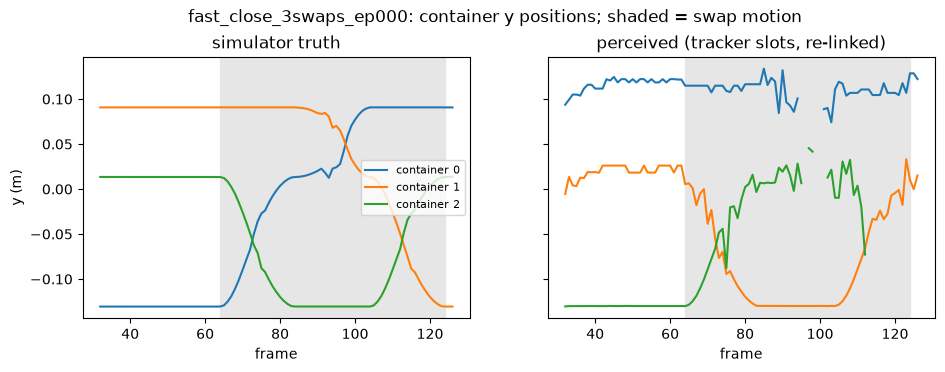

In [4]:
nb = d["meta"]["n_bins"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for k, (arr, title) in enumerate(((d["oracle"], "simulator truth"), (d["perceived"], "perceived (tracker slots, re-linked)"))):
    for s in range(nb):
        ax[k].plot(arr[:, s, F_X + 1], label=f"container {s}")
    for t0, t1 in d["meta"]["schedule"]:
        ax[k].axvspan(t0, t1, color="0.9")
    ax[k].set_title(title); ax[k].set_xlabel("frame")
ax[0].set_ylabel("y (m)"); ax[0].legend(fontsize=8)
plt.suptitle(f"{d['name']}: container y positions; shaded = swap motion", y=1.02); plt.show()

## 2. The prototype on one episode

`ArbiterKBSystem` consumes one observation table (`FrameObs`) per frame, strictly causally. Each step runs
*observe → detectors → rules → `KB.apply`*. Every item in the KB is a belief with support ids that lead back to
observations. Below: what a controller would read in arm **K** (the KB view) and in arm **R** (the raw tracker log),
from the same perception.

In [5]:
kb_sys = c3.make("kb", "min_3d", 0.02, PARAMS)
kb_sys.reset(src.meta(demo))
frames = list(src.frames(demo))
t0 = time.perf_counter()
for f in frames:
    kb_sys.step(f)
dt = (time.perf_counter() - t0) / len(frames)
kb = kb_sys.kb
print(f"{len(frames)} frames, {dt * 1e3:.2f} ms per KB update; {len(kb.evidence)} evidence items, {len(kb.events)} events")

view_k = controller_view(kb, PARAMS.rule)
view_r = f"Goal: {src.meta(demo).task_goal}\nRaw tracker log (every 10th frame):\n" + raw_tracker_log(frames)
print(f"\n=== arm K: the KB view ({len(view_k)} chars, ~{len(view_k) // 4} tokens) ===\n")
print(view_k)

127 frames, 0.08 ms per KB update; 80 evidence items, 6 events

=== arm K: the KB view (4247 chars, ~1061 tokens) ===

Goal: pick up the container that hides the blue cube
Progress: covers 3, close passes 3
Task items (named by the goal): container, blue cube
Objects (world frame, m):
  [bin_0] container (task item), visible at -0.057, 0.122, 0.050, last seen t=126 [o126:bin_0]
  [bin_1] container (task item), visible at 0.077, 0.015, 0.067, last seen t=126 [o126:bin_1]
  [bin_2] container (task item), visible at 0.044, -0.089, 0.006, last seen t=115 [o115:bin_2]
  [cube_blue] blue cube (task item), hidden: see Inside below, last seen t=31
  [cube_green] green cube, hidden: see Inside below, last seen t=31
  [cube_red] red cube, hidden: see Inside below, last seen t=31
Relations:
  [Inside(cube_blue)] bin_2 0.93 | bin_1 0.06 | elsewhere 0.01 | bin_0 0.01  [e7,e71,o32:bin_2]
  [Inside(cube_green)] bin_0 0.98 | elsewhere 0.01 | bin_2 0.01 | bin_1 0.00  [e71,e8,o32:bin_0]
  [Inside(cube_r

In [6]:
print(f"=== arm R: the raw tracker log ({len(view_r)} chars, ~{len(view_r) // 4} tokens), first 12 lines ===\n")
print("\n".join(view_r.splitlines()[:12]), "\n...")

=== arm R: the raw tracker log (2038 chars, ~509 tokens), first 12 lines ===

Goal: pick up the container that hides the blue cube
Raw tracker log (every 10th frame):
t=0: bin_0 hidden; bin_1 hidden; bin_2 hidden; cube_blue -0.074, -0.133, 0.025; cube_green -0.037, 0.094, 0.026; cube_red 0.100, 0.015, 0.030
t=10: bin_0 hidden; bin_1 hidden; bin_2 hidden; cube_blue -0.074, -0.133, 0.024; cube_green -0.038, 0.095, 0.025; cube_red 0.101, 0.015, 0.029
t=20: bin_0 hidden; bin_1 hidden; bin_2 hidden; cube_blue -0.074, -0.133, 0.024; cube_green -0.038, 0.095, 0.024; cube_red 0.101, 0.015, 0.029
t=30: bin_0 hidden; bin_1 hidden; bin_2 hidden; cube_blue -0.074, -0.133, 0.024; cube_green -0.037, 0.095, 0.024; cube_red 0.101, 0.015, 0.029
t=40: bin_0 -0.101, 0.112, 0.038; bin_1 0.076, 0.019, 0.044; bin_2 -0.067, -0.130, 0.047; cube_blue hidden; cube_green hidden; cube_red hidden
t=50: bin_0 -0.062, 0.122, 0.026; bin_1 0.077, 0.018, 0.031; bin_2 -0.067, -0.130, 0.047; cube_blue hidden; cube_green 

In [7]:
t = truth(d)
print("Which container hides each cube?  KB belief (support ids) vs truth\n")
for cube in sorted(k[3:] for k in t if k.startswith("q1_")):
    dist = kb_sys.believe_inside("cube_" + cube)
    top, p = dist.argmax()
    print(f"cube_{cube:<6} KB: {dist.as_dict()}  top={top} p={p:.2f} | truth: {t['q1_' + cube]} "
          f"| tracker swapped this container: {t['swapped'][cube]}")
print("\nlast event-log lines (what the controller can cite):")
print("\n".join(event_log(kb, last=8)))

Which container hides each cube?  KB belief (support ids) vs truth

cube_blue   KB: {'None': 0.01, 'bin_0': 0.008137, 'bin_1': 0.055412, 'bin_2': 0.926452}  top=bin_2 p=0.93 | truth: ['bin_0'] | tracker swapped this container: True
cube_red    KB: {'None': 0.01, 'bin_0': 0.000319, 'bin_1': 0.93442, 'bin_2': 0.055261}  top=bin_1 p=0.93 | truth: ['bin_1'] | tracker swapped this container: False

last event-log lines (what the controller can cite):
(30 earlier lines omitted)
[v1] t=32 cube_blue covered by bin_2 at (-0.07, -0.13) (conf 0.99) [e7]; from then on it moves with bin_2
[v2] t=32 cube_green covered by bin_0 at (-0.04, 0.09) (conf 0.99) [e8]; from then on it moves with bin_0
[v3] t=32 cube_red covered by bin_1 at (0.10, 0.02) (conf 0.99) [e9]; from then on it moves with bin_1
[e69] t=110 bin_0 moved (-0.05, 0.12) -> (-0.07, 0.11) (t=105-110)
[e70] t=113 bin_2 disappeared at (0.04, -0.07)
[e71] t=113 bin_1, bin_2 passed close to each other, closest 6.4 cm (detected)
[v6] t=113 bin_

## 3. Belief operations

Three operations carry the uncertainty (paper §4.3): the **cover kernel** (R1) spreads a newly hidden cube over the
nearby containers, **swap mixing** (R6) exchanges mass between two containers that passed close to each other, and
**exclusivity** (R5) combines cubes covered in the same frame under "one cube per container".

In [8]:
cover = Distribution.from_distances({"bin_0": 0.010, "bin_1": 0.045, "bin_2": 0.120}, sigma=PARAMS.rule.sigma_cover,
                                    t=40, support={"bin_0": ["e1"], "bin_1": ["e1"], "bin_2": ["e1"]})
print("R1 cover kernel :", {k: round(v, 3) for k, v in cover.as_dict().items()})
for d_min in (0.05, 0.07, 0.10):
    w = PARAMS.rule.w_max * np.exp(-d_min / PARAMS.rule.d0)
    mixed = cover.swap_mix("bin_0", "bin_1", w, t=70, ev_id="e9")
    print(f"R6 pass at {d_min * 100:.0f} cm: w = {w:.3f} ->", {k: round(v, 3) for k, v in mixed.as_dict().items()})
a = Distribution.from_distances({"bin_0": 0.01, "bin_1": 0.03}, 0.02, 40, {"bin_0": ["e1"], "bin_1": ["e1"]})
b = Distribution.from_distances({"bin_0": 0.02, "bin_1": 0.02}, 0.02, 40, {"bin_0": ["e2"], "bin_1": ["e2"]})
print("R5 exclusivity  :", {c: {k: round(v, 3) for k, v in x.as_dict().items()}
                            for c, x in joint_exclusive({"cube_red": a, "cube_blue": b}, 40).items()})

R1 cover kernel : {'bin_0': 0.917, 'bin_1': 0.083, 'bin_2': 0.0}
R6 pass at 5 cm: w = 0.041 -> {'bin_0': 0.883, 'bin_1': 0.117, 'bin_2': 0.0}
R6 pass at 7 cm: w = 0.015 -> {'bin_0': 0.905, 'bin_1': 0.095, 'bin_2': 0.0}
R6 pass at 10 cm: w = 0.003 -> {'bin_0': 0.914, 'bin_1': 0.086, 'bin_2': 0.0}
R5 exclusivity  : {'cube_red': {'bin_0': 0.731, 'bin_1': 0.269}, 'cube_blue': {'bin_0': 0.269, 'bin_1': 0.731}}


At G's real swap distances (5–9 cm) R6's weight with the frozen d0 = 2 cm is small (about 0.005–0.04). This is the
quantitative reason for the overconfidence on tracker-swapped cubes reported in §5.4.

## 4. H3: is the KB's probability calibrated? (G train, recomputed here)

No LLM is involved: H3 concerns the probability the KB itself attaches to its answer, which a controller can read
directly. For each cube whose true container is still tracked at the end (241 train cubes), every system gives its
most likely container and that answer's probability *p*.

* **Bound**: the cube follows its covering container with p = 1 (Ledger-style cover-following, no uncertainty).
* **SoftHaircut**: Bound, with R6's swap score applied as a haircut on p (the same feature and formula, no KB).
* **ArbiterKB**: R1–R6 inside the KB.

Metrics: accuracy, AUROC of p for right vs wrong, and AURC (area under the risk–coverage curve; lower is better).
Scales were chosen on train by AURC; the choice is frozen in `results/latest/claim3_g/choice.json`.

In [9]:
choice = json.loads((LATEST / "claim3_g" / "choice.json").read_text())
settings = {"Bound": ("bound", "min_3d", 0.02)}
settings |= {f"{'SoftHaircut' if n.startswith('soft') else 'ArbiterKB'} {n.split('/')[1]}":
             (n.split("/")[0], n.split("/")[1], float(n.split("/")[2])) for n in choice.values()}
t0 = time.perf_counter()
rows = c3.run("train", settings, PARAMS)
print(f"computed in {time.perf_counter() - t0:.0f} s\n")
print(f"{'system':<22}{'n':>5}{'acc':>7}{'AUROC':>8}{'AURC':>8}{'AURC stress':>13}{'AUROC clean-vs-swapped':>24}")
for name, r in rows.items():
    m = c3.metrics(r)
    print(f"{name:<22}{m['n']:>5}{m['acc']:>7.3f}{m['auroc']:>8.3f}{m['aurc']:>8.3f}{m['aurc_stress']:>13.3f}"
          f"{m['auroc_clean_vs_swapped']:>24.3f}")

computed in 13 s

system                    n    acc   AUROC    AURC  AURC stress  AUROC clean-vs-swapped
Bound                   241  0.834   0.500   0.166        0.185                   0.500
SoftHaircut min_3d      241  0.834   0.659   0.121        0.133                   0.735
SoftHaircut min_q       241  0.834   0.667   0.117        0.132                   0.750
ArbiterKB min_3d        241  0.846   0.694   0.099        0.108                   0.720
ArbiterKB min_q         241  0.846   0.714   0.095        0.103                   0.744


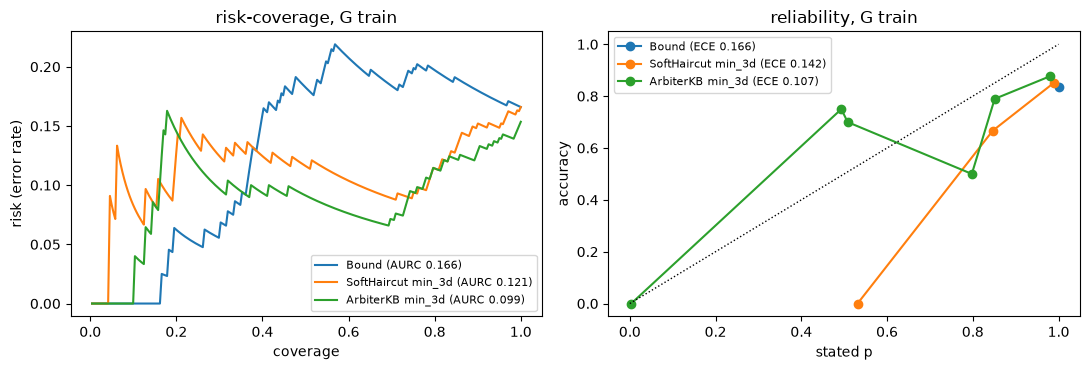

In [10]:
def risk_coverage(r):
    p = np.array([x["p"] for x in r]); ok = np.array([x["right"] for x in r])
    order = np.argsort(-p, kind="stable")
    cov = np.arange(1, len(p) + 1) / len(p)
    return cov, np.cumsum(~ok[order]) / np.arange(1, len(p) + 1)

def reliability(r, bins=10):
    p = np.array([x["p"] for x in r]); ok = np.array([x["right"] for x in r], float)
    idx = np.minimum((p * bins).astype(int), bins - 1)
    out = [(p[idx == b].mean(), ok[idx == b].mean(), (idx == b).sum()) for b in range(bins) if (idx == b).any()]
    ece = sum(n * abs(c - a) for c, a, n in out) / len(p)
    return out, ece

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for name in ("Bound", "SoftHaircut min_3d", "ArbiterKB min_3d"):
    ax[0].plot(*risk_coverage(rows[name]), label=f"{name} (AURC {c3.aurc(rows[name]):.3f})")
    pts, ece = reliability(rows[name])
    ax[1].plot([c for c, _, _ in pts], [a for _, a, _ in pts], "o-", label=f"{name} (ECE {ece:.3f})")
ax[0].set_xlabel("coverage"); ax[0].set_ylabel("risk (error rate)"); ax[0].set_title("risk-coverage, G train"); ax[0].legend(fontsize=8)
ax[1].plot([0, 1], [0, 1], "k:", lw=1); ax[1].set_xlabel("stated p"); ax[1].set_ylabel("accuracy"); ax[1].set_title("reliability, G train"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [11]:
kb_rows, soft_rows = rows["ArbiterKB min_3d"], rows["SoftHaircut min_3d"]
print("paired bootstrap over episodes (1,000 draws): ArbiterKB - SoftHaircut, min_3d, G train")
print("  AURC  diff [95% CI]:", c3.paired(kb_rows, soft_rows, c3.aurc))
print("  AUROC diff [95% CI]:", c3.paired(kb_rows, soft_rows, c3.auroc_of))

swapped = [r for r in kb_rows if r["swapped"]]
clean = [r for r in kb_rows if r["swapped"] is False]
wrong = [r for r in kb_rows if not r["right"]]
print(f"\nmagnitude: median p on tracker-swapped cubes {np.median([r['p'] for r in swapped]):.2f} (n={len(swapped)}), "
      f"on clean cubes {np.median([r['p'] for r in clean]):.2f} (n={len(clean)}); "
      f"share of wrong answers with p >= 0.9: {np.mean([r['p'] >= 0.9 for r in wrong]):.2f}")

paired bootstrap over episodes (1,000 draws): ArbiterKB - SoftHaircut, min_3d, G train
  AURC  diff [95% CI]: [-0.0221, -0.0608, 0.0118]


  AUROC diff [95% CI]: [0.0353, -0.0383, 0.1265]

magnitude: median p on tracker-swapped cubes 0.95 (n=31), on clean cubes 0.99 (n=193); share of wrong answers with p >= 0.9: 0.68


**Attribution (train).** Which part of the KB produces its lead? (a) R6 off, (b) no cover kernel or floor, (c) R5 off,
(d) cover only (R6 and R5 off).

In [12]:
abl = {n: ("kb", "min_3d", 0.02, over, skip) for n, (over, skip) in c3.ABLATE.items()}
arows = c3.run("train", abl, PARAMS)
print(f"{'variant':<16}{'acc':>7}{'AUROC':>8}{'AURC':>8}   AURC diff vs full KB [95% CI]")
for n, r in arows.items():
    m = c3.metrics(r)
    diff = "" if n == "kb" else c3.paired(r, arows["kb"], c3.aurc)
    print(f"{n:<16}{m['acc']:>7.3f}{m['auroc']:>8.3f}{m['aurc']:>8.3f}   {diff}")

variant             acc   AUROC    AURC   AURC diff vs full KB [95% CI]
kb                0.846   0.694   0.099   
kb-R6off          0.846   0.555   0.139   [0.04, 0.0019, 0.0778]


kb-nokernel       0.846   0.680   0.106   [0.0068, -0.0096, 0.0284]
kb-R5off          0.846   0.694   0.099   [-0.0003, -0.0012, 0.0]


kb-coveronly      0.846   0.556   0.139   [0.0396, 0.0019, 0.0773]


## 5. The committed G test read (loaded, not recomputed)

Test-split reads are allowed only with a frozen parameter file and are appended to `results/test_reads.log` (one read
per registered question). The notebook therefore **loads** the stored read instead of running it again.

In [13]:
read = json.loads((LATEST / "claim3_g" / "read.json").read_text())
abt = json.loads((LATEST / "claim3_g" / "ablate_test.json").read_text())
print(f"{'system (G test)':<22}{'n':>5}{'acc':>7}{'AUROC':>8}{'AURC':>8}{'AUROC clean-vs-swapped':>24}")
for n, m in read["table"].items():
    print(f"{n:<22}{m['n']:>5}{m['acc']:>7.3f}{m['auroc']:>8.3f}{m['aurc']:>8.3f}{m['auroc_clean_vs_swapped']:>24.3f}")
print("\npaired (diff, 2.5%, 97.5%):")
for k, v in read["pairs"].items():
    print(" ", k, v)
print("\nablations on test (post hoc), AURC diff vs full KB:")
for k, v in abt["pairs"].items():
    print(" ", k, v["aurc"])
print("\nledger lines for claim 3:")
print("\n".join(l for l in (ROOT / "results" / "test_reads.log").read_text().splitlines() if "claim 3" in l))

system (G test)           n    acc   AUROC    AURC  AUROC clean-vs-swapped
bound                   235  0.821   0.500   0.179                   0.500
soft/min_3d/0.02        235  0.821   0.640   0.139                   0.812
soft/min_q/0.05         235  0.817   0.608   0.147                   0.703
kb/min_3d/0.02          235  0.817   0.742   0.104                   0.812
kb/min_q/0.05           235  0.809   0.723   0.115                   0.763

paired (diff, 2.5%, 97.5%):
  kb-soft/min_3d {'aurc': [-0.0343, -0.0694, -0.0039], 'auroc': [0.1019, 0.0317, 0.1922]}
  kb-soft/min_q {'aurc': [-0.0326, -0.0691, 0.0042], 'auroc': [0.1148, 0.0332, 0.2009]}
  kb_min_q-kb_min_3d {'aurc': [0.0105, 0.0014, 0.0215]}

ablations on test (post hoc), AURC diff vs full KB:
  kb-R6off-kb [0.0532, 0.0031, 0.1004]
  kb-nokernel-kb [0.0368, 0.0099, 0.0694]
  kb-R5off-kb [-0.0007, -0.0023, 0.0001]
  kb-coveronly-kb [0.052, 0.0022, 0.0996]
  kb-soft [-0.0343, -0.0694, -0.0039]

ledger lines for claim 3:
2026-

## 6. Offline LLM results (loaded from committed summaries)

These rows required paid calls to `qwen/qwen3.6-35b-a3b` (OpenRouter); the answers are cached locally but the cache
(about 0.5 GB) is not shipped. The summaries below are the committed outputs.

**Q1** = "which container hides each cube?", answered by the LLM from arm K (the KB view) or arm R (the raw tracker
log), with reasoning off or at the default effort. *KB top answer* is the KB's own most likely container, no LLM.

In [14]:
def show_q1(path, title, kb_top=None):
    rep = json.loads(Path(path).read_text())["report"]
    print(title)
    if kb_top is not None:
        print(f"  {'KB top answer, no LLM':<26} Q1 {kb_top:.3f}")
    for k, v in rep.items():
        if "-" in k.split("/")[1]:
            continue
        lo, hi = v["q1"][1], v["q1"][2]
        print(f"  {k:<26} Q1 {v['q1'][0]:.3f} [{lo:.3f}, {hi:.3f}]  stress {v['q1_stress'][0]:.3f}  "
              f"tracker-swapped {v['q1_swapped'][0]:.3f}  prompt tokens {v['prompt_tokens_median']}")
    for k, v in rep.items():
        if "-" in k.split("/")[1]:
            print(f"  paired {k}: {json.dumps(v)[:160]}")

base = json.loads((LATEST / "perceived_qa_A" / "baselines.json").read_text()) if (LATEST / "perceived_qa_A" / "baselines.json").exists() else {}
show_q1(LATEST / "perceived_qa_relinked" / "summary.json", "G train (re-linked tracks):")
print()
show_q1(LATEST / "perceived_qa_test" / "summary.json", "G test (re-linked tracks, one read):",
        kb_top=read["table"]["kb/min_q/0.05"]["acc"])

G train (re-linked tracks):
  relinked/K/default         Q1 0.846 [0.796, 0.887]  stress 0.829  tracker-swapped 0.129  prompt tokens 2484
  relinked/K/off             Q1 0.851 [0.800, 0.890]  stress 0.834  tracker-swapped 0.129  prompt tokens 2486
  relinked/R/default         Q1 0.685 [0.623, 0.740]  stress 0.687  tracker-swapped 0.065  prompt tokens 1502
  relinked/R/off             Q1 0.548 [0.485, 0.609]  stress 0.550  tracker-swapped 0.129  prompt tokens 1504
  paired relinked/K-R/default: {"all": [0.15, 0.083, 0.22], "stock": [0.3, 0.1, 0.5], "stress": [0.131, 0.058, 0.198]}
  paired relinked/K-R/off: {"all": [0.293, 0.213, 0.376], "stock": [0.433, 0.167, 0.667], "stress": [0.275, 0.19, 0.365]}

G test (re-linked tracks, one read):
  KB top answer, no LLM      Q1 0.809
  relinked/K/default         Q1 0.809 [0.753, 0.854]  stress 0.782  tracker-swapped 0.091  prompt tokens 2502
  relinked/K/off             Q1 0.813 [0.758, 0.857]  stress 0.786  tracker-swapped 0.121  prompt tokens 

In [15]:
print("Counting tasks from robot state (RoboMME dataset episodes 61-100; decision accuracy, Wilson 95%):")
cc = json.loads((LATEST / "count_controls" / "report_61_100.json").read_text())
for k, v in cc["cells"].items():
    arm = "/".join(k.split("/")[-2:])
    print(f"  {arm:<14} {v['right'][0]:.3f} [{v['right'][1]:.3f}, {v['right'][2]:.3f}]  n={v['n']}  "
          f"Pick {v['PickXtimes']:.2f}  Swing {v['SwingXtimes']:.2f}  BinFill {v['BinFill']:.2f}  tokens in {v['tokens_in']}")
print("\nRULE = no per-decision LLM (the KB's count against the parsed goal); K = KB view; PC = raw log + counter;"
      "\nK3 = earlier view; P = raw robot log; KO = oracle: the dataset's completed subgoals as text (upper reference).")

Counting tasks from robot state (RoboMME dataset episodes 61-100; decision accuracy, Wilson 95%):
  K/default      0.952 [0.922, 0.970]  n=310  Pick 0.98  Swing 0.88  BinFill 0.98  tokens in 368
  K/off          0.965 [0.938, 0.980]  n=310  Pick 1.00  Swing 0.88  BinFill 1.00  tokens in 370
  K3/default     0.935 [0.902, 0.958]  n=310  Pick 0.91  Swing 0.88  BinFill 1.00  tokens in 352
  K3/off         0.826 [0.780, 0.864]  n=310  Pick 0.78  Swing 0.71  BinFill 0.96  tokens in 354
  KO/default     0.990 [0.972, 0.997]  n=310  Pick 1.00  Swing 0.97  BinFill 1.00  tokens in 237
  KO/off         0.965 [0.938, 0.980]  n=310  Pick 1.00  Swing 0.92  BinFill 0.97  tokens in 239
  P/default      0.819 [0.773, 0.858]  n=310  Pick 0.99  Swing 0.43  BinFill 0.99  tokens in 1274
  P/off          0.610 [0.554, 0.662]  n=310  Pick 0.72  Swing 0.41  BinFill 0.67  tokens in 1276
  PC/default     0.903 [0.865, 0.931]  n=310  Pick 1.00  Swing 0.70  BinFill 0.98  tokens in 1289
  PC/off         0.855 [0.

## 7. Closed-loop experiment (H1, H2): placeholders and statistical plan

> **Work in progress.** The 2610.17350 waypoint loop is ported (`arbiter_kb/closed_loop.py`) and the online perception
> path reproduces the batch source exactly on all 180 G episodes (158,427 object-frames, 0 differences). The pod
> smoke test is running; arm H solved VideoUnmaskSwap validation episode 0 in 3 calls ($0.007). No success rates
> exist yet, so the table below is a placeholder.

Per episode, the runner records: success (RoboMME's check), calls, input tokens, images, dollars, wall time, and the
failure type. The comparisons are paired over the same episodes and seeds.

In [16]:
ARMS = {"H": "full image history (2610.17350's memory)", "R": "raw tracker log + current frames",
        "K": "ArbiterKB view + current frames", "S": "one sentence per hidden object (the KB's argmax)",
        "K0": "current object table only (no history)"}
TASKS = ("VideoUnmaskSwap", "VideoPlaceOrder", "further tasks")  # the val pilot's two tasks first
print(f"{'arm':<4}{'memory':<50}" + "".join(f"{t:>18}" for t in TASKS) + f"{'tokens/ep':>11}{'images/ep':>11}{'$/ep':>7}")
for a, desc in ARMS.items():
    print(f"{a:<4}{desc:<50}" + "".join(f"{'TBD':>18}" for _ in TASKS) + f"{'TBD':>11}{'TBD':>11}{'TBD':>7}")

arm memory                                               VideoUnmaskSwap   VideoPlaceOrder     further tasks  tokens/ep  images/ep   $/ep
H   full image history (2610.17350's memory)                         TBD               TBD               TBD        TBD        TBD    TBD
R   raw tracker log + current frames                                 TBD               TBD               TBD        TBD        TBD    TBD
K   ArbiterKB view + current frames                                  TBD               TBD               TBD        TBD        TBD    TBD
S   one sentence per hidden object (the KB's argmax)                 TBD               TBD               TBD        TBD        TBD    TBD
K0  current object table only (no history)                           TBD               TBD               TBD        TBD        TBD    TBD


In [17]:
# How many episodes does a paired comparison need? Minimum detectable difference in success for a paired design,
# from the discordant-pair rate (McNemar, two-sided alpha 0.05, power 0.8), and the Wilson half-width per arm.
from scipy.stats import norm

def mde_paired(n, discordant):
    za, zb = norm.ppf(0.975), norm.ppf(0.8)
    return (za + zb) * np.sqrt(discordant / n)

for n in (20, 50, 100, 150):
    lo, hi = wilson(int(0.8 * n), n)
    print(f"n={n:>3}: Wilson 95% half-width at 80% success {100 * (hi - lo) / 2:4.1f} pp; "
          f"paired MDE with 20% / 40% discordant pairs: {100 * mde_paired(n, 0.2):4.1f} / {100 * mde_paired(n, 0.4):4.1f} pp")

n= 20: Wilson 95% half-width at 80% success 16.8 pp; paired MDE with 20% / 40% discordant pairs: 28.0 / 39.6 pp
n= 50: Wilson 95% half-width at 80% success 10.9 pp; paired MDE with 20% / 40% discordant pairs: 17.7 / 25.1 pp
n=100: Wilson 95% half-width at 80% success  7.8 pp; paired MDE with 20% / 40% discordant pairs: 12.5 / 17.7 pp
n=150: Wilson 95% half-width at 80% success  6.4 pp; paired MDE with 20% / 40% discordant pairs: 10.2 / 14.5 pp


**Proposed decision rules, to be committed before the runs** (paper §6.3; the project registers every rule before its run): *K matches H* if the paired 95% bootstrap CI of K − H lies within
±10 pp; H2 is supported if K matches H at under 25% of H's input tokens and images per episode; H1 is supported if K
with the small model matches the reference row's success within the same margin and beats H with the small model.
Every success number is reported with its Wilson interval; every comparison with a paired episode bootstrap
(the same `c3.paired` used in §4).